## **Optimization of CLAHE enhancement - metrics Laplacian, entropy, PSNR and SSIM**

In [ ]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os
import numpy as np
import pandas as pd
import shutil
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import cv2

In [ ]:
# Replace these with your own credentials
os.environ['KAGGLE_USERNAME'] = 'himadeepthi'
os.environ['KAGGLE_KEY'] = '884683d5908a6cbf0e7d858dbe256ba5'

In [ ]:
#!pip install -q kaggle
#!kaggle datasets download -d nikhilroxtomar/brain-tumor-segmentation
#!unzip -q brain-tumor-segmentation.zip -d brain_tumor_data

In [ ]:
!pip install -q kaggle

# Download the dataset

!kaggle datasets download -d sovitrath/diabetic-retinopathy-224x224-2019-data

# Unzip it
!unzip -q diabetic-retinopathy-224x224-2019-data.zip -d diabetic_retinopathy_data

Dataset URL: https://www.kaggle.com/datasets/sovitrath/diabetic-retinopathy-224x224-2019-data
License(s): CC0-1.0
 52% 125M/238M [00:00<00:00, 1.30GB/s]
100% 238M/238M [00:00<00:00, 814MB/s] 


In [ ]:
# ==== CONFIGURATION ====
DATA_DIR = "diabetic_retinopathy_data/colored_images"
SPLIT_DIR = "split_data"
#TEST_DIR = "test_data" # Add a directory for test data
NUM_CLASSES = 5
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 5

In [ ]:
SPLIT_DIR = "split_data"

if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)
    print(f"Deleted '{SPLIT_DIR}' directory and its contents.")
else:
    print(f"'{SPLIT_DIR}' does not exist.")

Deleted 'split_data' directory and its contents.


In [ ]:
# Original dataset directory with class folders
original_data_dir = 'diabetic_retinopathy_data/colored_images'

# Output directories
output_base = 'split_data'
train_dir = os.path.join(output_base, 'train')
val_dir = os.path.join(output_base, 'val')
test_dir = os.path.join(output_base, 'test')

# CSV output paths
train_csv_path = os.path.join(output_base, 'train.csv')
val_csv_path = os.path.join(output_base, 'val.csv')
test_csv_path = os.path.join(output_base, 'test.csv') # Test CSV path

# Define the label mapping (should match the one in the DRDataset)
label_map = {'No_DR': 0, 'Mild': 1, 'Moderate': 2, 'Severe': 3, 'Proliferate_DR': 4}

# Make output directories based on integer labels
for d in [train_dir, val_dir, test_dir]: # Include test_dir
    # Create directories for each integer label
    for i in range(len(label_map)):
        os.makedirs(os.path.join(d, str(i)), exist_ok=True)

# Collect all image paths and labels
data = []
for label_str in os.listdir(original_data_dir):
    class_dir = os.path.join(original_data_dir, label_str)
    if os.path.isdir(class_dir) and label_str in label_map: # Only process valid label directories
        label_int = label_map[label_str]
        for fname in os.listdir(class_dir):
            full_path = os.path.join(class_dir, fname)
            # Store the integer label in the data list and the dataframe
            data.append((full_path, fname, label_str, label_int)) # Store both string and integer label

# Create a DataFrame, including the integer label column
df = pd.DataFrame(data, columns=['path', 'filename', 'label_str', 'label_int'])

# Split into train, validation, and test sets
# First split for train (60%) and temp (40% for validation + test)
train_df, temp_df = train_test_split(df, test_size=0.5, stratify=df['label_str'], random_state=42)
# Second split for validation (20% of original, which is 50% of temp) and test (20% of original, which is 50% of temp)
val_df, test_df = train_test_split(temp_df, test_size=0.4, stratify=temp_df['label_str'], random_state=42) # 0.5 of 0.4 is 0.2

# Function to copy files, now copies to integer label directories
def copy_images(df, target_dir):
    for _, row in df.iterrows():
        # Use the integer label for the destination directory
        dest = os.path.join(target_dir, str(row['label_int']), row['filename'])
        # Ensure the source path is correct (from the original data_dir structure)
        src = os.path.join(original_data_dir, row['label_str'], row['filename'])
        shutil.copy(src, dest)

# Copy images to respective folders
copy_images(train_df, train_dir)
copy_images(val_df, val_dir)
copy_images(test_df, test_dir) # Copy test set images

# Save CSVs - let's save filename and the integer label
train_df[['filename', 'label_int']].rename(columns={'label_int': 'label'}).to_csv(train_csv_path, index=False)
val_df[['filename', 'label_int']].rename(columns={'label_int': 'label'}).to_csv(val_csv_path, index=False)
test_df[['filename', 'label_int']].rename(columns={'label_int': 'label'}).to_csv(test_csv_path, index=False) # Save test CSV

print("✅ Split complete. Train and validation images and CSVs are saved in:", output_base)
print("✅ Test images and CSV are saved in:", output_base)

# Ensure the first DRDataset class is used, as it expects the CSV with integer labels
# and constructs the path correctly based on integer labels.

✅ Split complete. Train and validation images and CSVs are saved in: split_data
✅ Test images and CSV are saved in: split_data


In [ ]:
# ==== DATA SPLIT ====
def split_data():
    os.makedirs(SPLIT_DIR, exist_ok=True)
    for phase in ['train', 'val', 'test']:
        for i in range(NUM_CLASSES):
            os.makedirs(os.path.join(SPLIT_DIR, phase, str(i)), exist_ok=True)

    data = []
    for label in os.listdir(DATA_DIR):
        class_path = os.path.join(DATA_DIR, label)
        if os.path.isdir(class_path):
            for fname in os.listdir(class_path):
                data.append((os.path.join(class_path, fname), fname, label))

    df = pd.DataFrame(data, columns=['path', 'filename', 'label'])
    train_df, val_df = train_test_split(df, test_size=0.5, stratify=df['label'], random_state=42)
    val_df, test_df = train_test_split(val_df, test_size=0.4, stratify=val_df['label'], random_state=42)

    def copy_data(df, phase):
        for _, row in df.iterrows():
            dest = os.path.join(SPLIT_DIR, phase, row['label'], row['filename'])
            shutil.copy(row['path'], dest)

    copy_data(train_df, 'train')
    copy_data(val_df, 'val')
    copy_data(test_df, 'test')

    train_df[['filename', 'label']].to_csv(os.path.join(SPLIT_DIR, 'train.csv'), index=False)
    val_df[['filename', 'label']].to_csv(os.path.join(SPLIT_DIR, 'val.csv'), index=False)
    test_df[['filename', 'label']].to_csv(os.path.join(SPLIT_DIR, 'test.csv'), index=False)

In [ ]:
# ==== DATASET CLASS ====
class DRDataset(Dataset):
      def __init__(self, csv_file, root_dir, transform=None, optimal_clache=False):
            self.df = pd.read_csv(csv_file)
            self.root_dir = root_dir
            self.transform = transform
            # Corrected the typo here
            self.optimal_clahe = optimal_clache
            # Add a flag for CLAHE

      def __len__(self):
            return len(self.df)

      def __getitem__(self, idx):
            row = self.df.iloc[idx]
            int_label = row['label']
            img_path = os.path.join(self.root_dir, str(int_label), row['filename'])

            # Load the image using PIL
            image = Image.open(img_path).convert('RGB') # Ensure image is in RGB format

            if self.optimal_clahe:
                # Convert PIL image to numpy array for OpenCV
                image_np = np.array(image)
                # Apply CLAHE
                best_clahe_image = optimal_clache(image_np) # Pass numpy array to optimal_clache
                # Convert the processed numpy array back to PIL Image
                image = Image.fromarray(best_clahe_image)


            label = int_label

            if self.transform:
               image = self.transform(image)

            return image, label

In [ ]:
train_df = pd.read_csv('split_data/train.csv')
val_df = pd.read_csv('split_data/val.csv')
test_df = pd.read_csv('split_data/test.csv')

print(f"Train set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Test set size: {len(test_df)}")

Train set size: 1831
Validation set size: 1098
Test set size: 733


In [ ]:
### class distribution

print("Train set class distribution:")
print(train_df['label'].value_counts().sort_index())

print("\nValidation set class distribution:")
print(val_df['label'].value_counts().sort_index())

print("\nTest set class distribution:")
print(test_df['label'].value_counts().sort_index())

Train set class distribution:
label
0    903
1    185
2    499
3     97
4    147
Name: count, dtype: int64

Validation set class distribution:
label
0    541
1    111
2    300
3     57
4     89
Name: count, dtype: int64

Test set class distribution:
label
0    361
1     74
2    200
3     39
4     59
Name: count, dtype: int64


In [ ]:
!pip install -q optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 386.6/386.6 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.5/242.5 kB 21.7 MB/s eta 0:00:00


In [ ]:
import optuna
from sklearn.metrics import mean_squared_error
from skimage.metrics import structural_similarity as ssim

In [ ]:
import cv2
from skimage.metrics import structural_similarity as ssim
import optuna # Ensure optuna is imported

# Objective function: maximize pixel-wise SSIM
def optimal_clache(image):
    # Define the reference CLAHE outside the main function flow
    def reference_clahe_helper(img):
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        img_lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(img_lab)
        l = clahe.apply(l)
        img_lab = cv2.merge((l, a, b))
        img_clahe = cv2.cvtColor(img_lab, cv2.COLOR_LAB2RGB)
        return img_clahe

    # Calculate the target image using the helper function
    target_img = reference_clahe_helper(image)

    # Define the objective function for Optuna
    def objective(trial):
        clip_limit = trial.suggest_float('clip_limit', 1.0, 8.0)
        tile_grid_size_val = trial.suggest_int('tile_grid_size', 4, 16, step=2)
        tile_grid_size = (tile_grid_size_val, tile_grid_size_val)

        # Apply CLAHE with current parameters
        clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
        img_lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(img_lab)
        l = clahe.apply(l)
        img_lab = cv2.merge((l, a, b))
        img_clahe = cv2.cvtColor(img_lab, cv2.COLOR_LAB2RGB)


        ssim_val = ssim(target_img.flatten(), img_clahe.flatten(), data_range=img_clahe.flatten().max() - img_clahe.flatten().min()) # Add data_range for SSIM

        return ssim_val


    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=20,show_progress_bar=False)

    # Show the best result
    best_clip = study.best_params['clip_limit']
    best_tile = study.best_params['tile_grid_size']
    best_tile_grid = (best_tile, best_tile)
    clahe = cv2.createCLAHE(clipLimit=best_clip, tileGridSize=best_tile_grid)
    img_lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(img_lab)
    l = clahe.apply(l)
    img_lab = cv2.merge((l, a, b))
    best_result = cv2.cvtColor(img_lab, cv2.COLOR_LAB2RGB)
    color=cv2.cvtColor(best_result, cv2.COLOR_RGB2BGR)

    denoised_img = cv2.fastNlMeansDenoising(color, None, 7, 4, 21)
    return denoised_img

In [ ]:
!pip install -q scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 7.1 MB/s eta 0:00:00


In [ ]:
import cv2
from skimage.metrics import structural_similarity as ssim
import optuna # Ensure optuna is imported

import numpy as np
from skopt import gp_minimize
from skimage import img_as_float, img_as_ubyte
from skimage.exposure import equalize_adapthist as clahe
from skimage.metrics import peak_signal_noise_ratio as psnr
from math import erf, erfc # Import erf and erfc
def optimal_clache(image):

    def objective(params):
      # Unpack the parameters from the list provided by gp_minimize
      grid_size_val = int(params[0])  # Convert grid_size to integer
      clip_limit = params[1]
      # Ensure grid_size is an odd number and at least 1
      #grid_size_val = max(4, grid_size_val if grid_size_val % 2 != 0 else grid_size_val + 1)
      clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(grid_size_val,grid_size_val))
      img_lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
      l, a, b = cv2.split(img_lab)
      l = clahe.apply(l)
      img_lab = cv2.merge((l, a, b))
      img_clahe = cv2.cvtColor(img_lab, cv2.COLOR_LAB2RGB)
      #enhanced_image = clahe(img_as_float(image), kernel_size=(grid_size_val, grid_size_val), clip_limit=clip_limit) # Use kernel_size and clip_limit
      return psnr(image, img_clahe)


    dimensions = [
        (2, 16),  # grid_size: integer between 1 and 20
        (2.0, 10.0) # clip_limit: float between 2.1 and 10.0
    ]


    # Perform Bayesian optimization
    # Pass the defined dimensions to gp_minimize
    # Changed 'ei' to 'EI' for the acq_func parameter
    res_gp = gp_minimize(objective, dimensions, n_calls=10, acq_func='EI', verbose=True)

    #res_gp =gp_minimize(func, dimensions, base_estimator=None, n_calls=100, n_random_starts=None, n_initial_points=10, initial_point_generator='random', acq_func='gp_hedge', acq_optimizer='auto', x0=None, y0=None, random_state=None, verbose=False, callback=None, n_points=10000, n_restarts_optimizer=5, xi=0.01, kappa=1.96, noise='gaussian', n_jobs=1, model_queue_size=None)[source][source]


    # Get optimal parameters
    # Access parameters from res_gp.x according to the order in 'dimensions'
    opt_grid_size, opt_clip_limit = res_gp.x
    opt_grid_size = int(opt_grid_size) # Convert optimal grid_size back to integer
    opt_grid_size = max(1, opt_grid_size if opt_grid_size % 2 != 0 else opt_grid_size + 1) # Ensure optimal grid_size is odd and at least 1

    # Apply CLAHE with optimal parameters
    # Use kernel_size and clip_limit for the clahe function
    #enhanced_image = clahe(img_as_float(image), kernel_size=(opt_grid_size, opt_grid_size), clip_limit=opt_clip_limit)
    clahe = cv2.createCLAHE(clipLimit=opt_grid_size, tileGridSize=(opt_grid_size,opt_grid_size))
    img_lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(img_lab)
    l = clahe.apply(l)
    img_lab = cv2.merge((l, a, b))
    final_clahe = cv2.cvtColor(img_lab, cv2.COLOR_LAB2RGB)
    return final_clahe
#target_img_gray = cv2.cvtColor(final_clahe, cv2.COLOR_BGR2GRAY)
#plt.imshow(target_img_gray, cmap='gray')
#plt.title('CLAHE Enhanced - Bayesian optimization')

In [ ]:

# ==== CNN CLASSIFIER ====
def get_classifier():

    model = models.resnet50(pretrained=True)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model

In [ ]:
# ==== TRAINING FUNCTION ====
def train_model(model, train_loader, val_loader, device):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    model.to(device)
    train_losses = []
    val_losses = []

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        print(f"Epoch {epoch+1}/{EPOCHS}, Loss: {running_loss/len(train_loader):.4f}")
        epoch_train_loss = running_loss / len(train_loader)
        train_losses.append(epoch_train_loss)
        print(f"Epoch {epoch+1}/{EPOCHS}, Train Loss: {epoch_train_loss:.4f}")
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item()

        epoch_val_loss = running_val_loss / len(val_loader)
        val_losses.append(epoch_val_loss)
        print(f"Epoch {epoch+1}/{EPOCHS}, Validation Loss: {epoch_val_loss:.4f}")

    return model, train_losses, val_losses

In [ ]:
# ==== EVALUATION FUNCTION ====
def evaluate_model(model, val_loader, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    print("\nClassification Report:\n")
    print(classification_report(all_labels, all_preds, digits=4))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(NUM_CLASSES), yticklabels=range(NUM_CLASSES))
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix for Densenet')
    plt.show()

In [ ]:
# ==== MAIN ====
def main():
    train_csv_path = os.path.join(SPLIT_DIR, 'train.csv')
    val_csv_path = os.path.join(SPLIT_DIR, 'val.csv')
    test_csv_path = os.path.join(SPLIT_DIR, 'test.csv') # Path to the test CSV

    transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor()
        # Add other transforms here if needed (e.g., normalization)
    ])

    # Instantiate datasets with CLAHE
    train_dataset = DRDataset(train_csv_path, os.path.join(SPLIT_DIR, 'train'), transform, optimal_clache=True)
    val_dataset = DRDataset(val_csv_path, os.path.join(SPLIT_DIR, 'val'), transform, optimal_clache=False) # No CLAHE on validation
    test_dataset = DRDataset(test_csv_path, os.path.join(SPLIT_DIR, 'test'), transform, optimal_clache=False) # Test dataset


    # Use the weighted sampler in the train_loader
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE) # Test data loader

    model = get_classifier()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    train_model(model, train_loader, val_loader, device)

    print("\nEvaluating on Validation Set:")
    evaluate_model(model, val_loader, device)

    #print("\nEvaluating on Test Set:")
    #evaluate_model(model, test_loader, device) # Evaluate on the test set
    return model, train_losses, val_losses

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Streaming output truncated to the last 5000 lines.
Current minimum: 14.7535
Iteration No: 5 started. Evaluating function at random point.
Iteration No: 5 ended. Evaluation done at random point.
Time taken: 0.0041
Function value obtained: 14.4771
Current minimum: 14.4771
Iteration No: 6 started. Evaluating function at random point.
Iteration No: 6 ended. Evaluation done at random point.
Time taken: 0.0040
Function value obtained: 14.4771
Current minimum: 14.4771
Iteration No: 7 started. Evaluating function at random point.
Iteration No: 7 ended. Evaluation done at random point.
Time taken: 0.0037
Function value obtained: 14.2101
Current minimum: 14.2101
Iteration No: 8 started. Evaluating function at random point.
Iteration No: 8 ended. Evaluation done at random point.
Time taken: 0.0039
Function value obtained: 17.3260
Current minimum: 14.2101
Iteration No: 9 started. Evaluating function at random point.
Iteration No: 9 ended. Evaluation done at random point.
Time taken: 0.0040
Functio

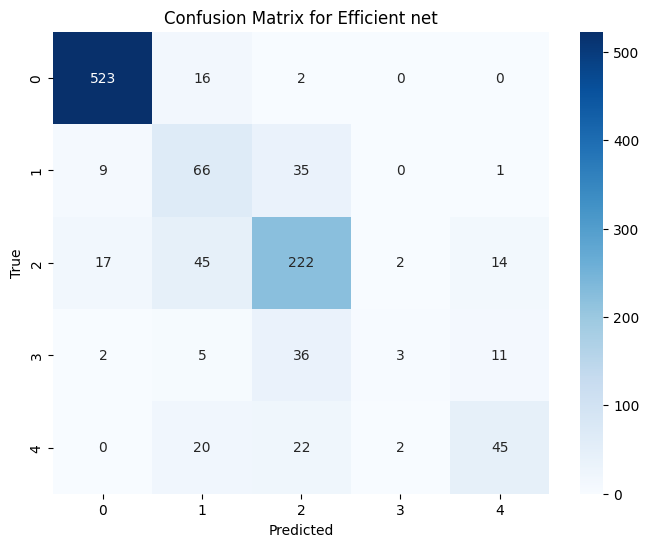

In [ ]:
if __name__ == '__main__':
    trained_model, train_losses, val_losses = main()

[I 2025-06-12 07:51:25,546] A new study created in memory with name: no-name-51959096-fa61-4331-928c-6f308ad0f20d
[I 2025-06-12 07:51:25,610] Trial 0 finished with value: 0.9834194104006063 and parameters: {'clip_limit': 3, 'tile_grid_size': 10}. Best is trial 0 with value: 0.9834194104006063.
[I 2025-06-12 07:51:25,737] Trial 1 finished with value: 0.9135372754215968 and parameters: {'clip_limit': 6, 'tile_grid_size': 12}. Best is trial 0 with value: 0.9834194104006063.
[I 2025-06-12 07:51:25,842] Trial 2 finished with value: 0.9365471847948259 and parameters: {'clip_limit': 5, 'tile_grid_size': 8}. Best is trial 0 with value: 0.9834194104006063.
[I 2025-06-12 07:51:25,932] Trial 3 finished with value: 0.9852304255763858 and parameters: {'clip_limit': 3, 'tile_grid_size': 12}. Best is trial 3 with value: 0.9852304255763858.
[I 2025-06-12 07:51:26,017] Trial 4 finished with value: 0.9759941534266627 and parameters: {'clip_limit': 1, 'tile_grid_size': 6}. Best is trial 3 with value: 0.9

Best ClipLimit: 2.0, Best TileGridSize: (14, 14)
Best SSIM: 0.99


Text(0.5, 1.0, 'Non-Linear Mean denoising')

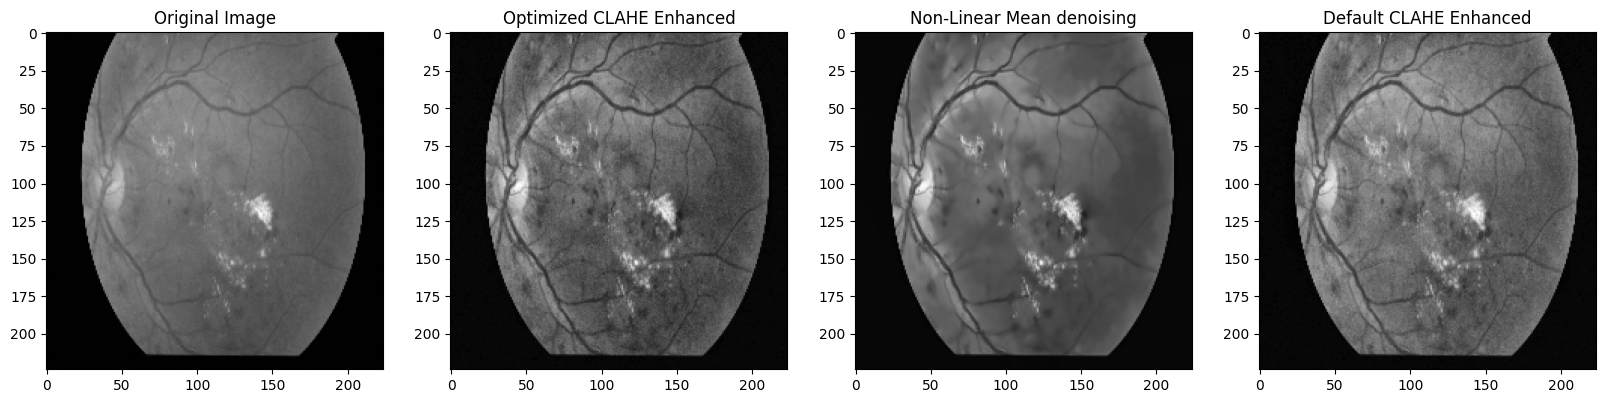

In [ ]:
plt.figure(figsize=(20, 6))
plt.subplot(1,4,1)
img_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(img_gray, cmap='gray')
plt.title('Original Image')
plt.subplot(1,4,2)
CLAHE_img_gray = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)
plt.imshow(CLAHE_img_gray, cmap='gray')
plt.title('Optimized CLAHE Enhanced')
plt.subplot(1,4,4)
target_img_gray = cv2.cvtColor(target_img, cv2.COLOR_BGR2GRAY)
plt.imshow(target_img_gray, cmap='gray')
plt.title('Default CLAHE Enhanced')
plt.subplot(1,4,3)
denoised_img_gray = cv2.cvtColor(denoised_img, cv2.COLOR_BGR2GRAY)
plt.imshow(denoised_img_gray, cmap='gray')
plt.title('Non-Linear Mean denoising')

In [ ]:
from skimage.measure import shannon_entropy
from skimage.metrics import structural_similarity as ssim
import math

laplacian_var = cv2.Laplacian(img_gray, cv2.CV_64F).var()
def_laplacian_var = cv2.Laplacian(target_img_gray, cv2.CV_64F).var()
Clahe_laplacian_var = cv2.Laplacian(CLAHE_img_gray, cv2.CV_64F).var()
Denoising_laplacian_var = cv2.Laplacian(denoised_img_gray, cv2.CV_64F).var()
print(f"Original Image Blur score: {laplacian_var:.2f}")
print(f"Optimized CLAHE Enhanced Blur score: {Clahe_laplacian_var:.2f}")
print(f"Non-Linear Mean denoising Blur score: {Denoising_laplacian_var:.2f}")
print(f"Default CLAHE Enhanced Blur score: {def_laplacian_var:.2f}")

entropy_val = shannon_entropy(img_gray)
Clahe_entropy_val = shannon_entropy(CLAHE_img_gray)
default_clahe_entropy_val = shannon_entropy(target_img_gray)
Denoising_entropy_val = shannon_entropy(denoised_img_gray)
print(f"Original Image Entropy: {entropy_val:.2f}")
print(f"Optimized CLAHE Enhanced Entropy: {Clahe_entropy_val:.2f}")
print(f"Non-Linear Mean denoising Entropy: {Denoising_entropy_val:.2f}")
print(f"Default CLAHE Enhanced Entropy: {default_clahe_entropy_val:.2f}")

mse_val = np.mean((img_gray - CLAHE_img_gray) ** 2)
def_mse_val = np.mean((img_gray - target_img_gray) ** 2)
denoising_mse_val = np.mean((img_gray - denoised_img_gray) ** 2)
print(f"Original Image MSE: {mse_val:.2f}")
print(f"Non-Linear Mean denoising MSE: {denoising_mse_val:.2f}")
print(f"Default CLAHE Enhanced MSE: {def_mse_val:.2f}")
# Handle potential division by zero if MSE is 0
psnr_val = 20 * math.log10(255.0 / math.sqrt(mse_val)) if mse_val > 0 else float('inf')
def_psnr_val = 20 * math.log10(255.0 / math.sqrt(def_mse_val)) if def_mse_val > 0 else float('inf')
denoising_psnr_val = 20 * math.log10(255.0 / math.sqrt(denoising_mse_val)) if denoising_mse_val > 0 else float('inf')
print(f"Original Image PSNR: {psnr_val:.2f}")
print(f"Default CLAHE Enhanced PSNR: {def_psnr_val:.2f}")
print(f"Non-Linear Mean denoising PSNR: {denoising_psnr_val:.2f}")

# SSIM requires images of the same size and type
ssim_val, _ = ssim(img_gray, CLAHE_img_gray, full=True)
denoising_ssim_val, _ = ssim(img_gray, denoised_img_gray, full=True)
def_ssim_val, _ = ssim(img_gray, target_img_gray, full=True)
print(f"Original Image SSIM: {ssim_val:.2f}")
print(f"Non-Linear Mean denoising SSIM: {denoising_ssim_val:.2f}")
print(f"Default CLAHE Enhanced SSIM: {def_ssim_val:.2f}")

Original Image Blur score: 406.80
Optimized CLAHE Enhanced Blur score: 4101.30
Non-Linear Mean denoising Blur score: 4010.81
Default CLAHE Enhanced Blur score: 3652.03
Original Image Entropy: 5.39
Optimized CLAHE Enhanced Entropy: 6.88
Non-Linear Mean denoising Entropy: 6.68
Default CLAHE Enhanced Entropy: 6.90
Original Image MSE: 92.74
Non-Linear Mean denoising MSE: 100.98
Default CLAHE Enhanced MSE: 100.34
Original Image PSNR: 28.46
Default CLAHE Enhanced PSNR: 28.12
Non-Linear Mean denoising PSNR: 28.09
Original Image SSIM: 0.38
Non-Linear Mean denoising SSIM: 0.39
Default CLAHE Enhanced SSIM: 0.40


In [ ]:
!pip install -q scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 2.7 MB/s eta 0:00:00


In [ ]:
import numpy as np
from skopt import gp_minimize
from skimage import img_as_float, img_as_ubyte
from skimage.exposure import equalize_adapthist as clahe
from skimage.metrics import peak_signal_noise_ratio as psnr
from math import erf, erfc # Import erf and erfc

image_path = '/content/diabetic_retinopathy_data/colored_images/Mild/0124dffecf29.png'
image1 = Image.open(image_path)
image = np.array(image1)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Define objective function: image quality metric (e.g., PSNR)
def objective(params):
   # Unpack the parameters from the list provided by gp_minimize
   grid_size_val = int(params[0])  # Convert grid_size to integer
   clip_limit = params[1]
   # Ensure grid_size is an odd number and at least 1
   #grid_size_val = max(4, grid_size_val if grid_size_val % 2 != 0 else grid_size_val + 1)
   enhanced_image = clahe(img_as_float(image), kernel_size=(grid_size_val, grid_size_val), clip_limit=clip_limit) # Use kernel_size and clip_limit
   # Calculate PSNR, ensuring both images are of the same data type and range
   # skimage.metrics.peak_signal_noise_ratio expects float images in range [0, 1]
   #return -psnr(img_as_float(image), enhanced_image) # Minimize negative PSNR to maximize PSNR
   #enhanced_image = clahe(img_as_float(image), grid_size=grid_size, clips=clip_limit)
   return psnr(image, enhanced_image)

# # Define acquisition function: EI
#def ei_acq_func(X):
#    mu, sigma = gp.predict(X, eval_MCMC=False)
#    return np.sqrt(np.pi) * sigma * (1 - erf(sigma)) + 0.5 * erfc((sigma**2 - 1) / (np.sqrt(2) * sigma))

# Define the search space for the hyperparameters (grid_size and clip_limit)
# Use a list of tuples to define the bounds for each parameter
dimensions = [
    (2, 16),  # grid_size: integer between 1 and 20
    (2.0, 10.0) # clip_limit: float between 2.1 and 10.0
]


# Perform Bayesian optimization
# Pass the defined dimensions to gp_minimize
# Changed 'ei' to 'EI' for the acq_func parameter
res_gp = gp_minimize(objective, dimensions, n_calls=10, acq_func='EI', verbose=True)

#res_gp =gp_minimize(func, dimensions, base_estimator=None, n_calls=100, n_random_starts=None, n_initial_points=10, initial_point_generator='random', acq_func='gp_hedge', acq_optimizer='auto', x0=None, y0=None, random_state=None, verbose=False, callback=None, n_points=10000, n_restarts_optimizer=5, xi=0.01, kappa=1.96, noise='gaussian', n_jobs=1, model_queue_size=None)[source][source]


# Get optimal parameters
# Access parameters from res_gp.x according to the order in 'dimensions'
opt_grid_size, opt_clip_limit = res_gp.x
opt_grid_size = int(opt_grid_size) # Convert optimal grid_size back to integer
opt_grid_size = max(1, opt_grid_size if opt_grid_size % 2 != 0 else opt_grid_size + 1) # Ensure optimal grid_size is odd and at least 1

# Apply CLAHE with optimal parameters
# Use kernel_size and clip_limit for the clahe function
enhanced_image = clahe(img_as_float(image), kernel_size=(opt_grid_size, opt_grid_size), clip_limit=opt_clip_limit)

# The acquisition function `ei_acq_func` was defined but not used in `gp_minimize` when `acq_func='ei'` is specified as a string.
# You can remove the `ei_acq_func` definition if you are using the built-in 'ei'.
# If you intended to use a custom acquisition function, you would pass the function itself to `acq_func`.
# For this fix, we will keep using the built-in 'ei'.
# The `gp` variable is not defined in the global scope or within the function.
# The acquisition function definition `ei_acq_func` relies on a `gp` object which is part of the internal working of `gp_minimize` when using custom acquisition functions.
# Since we are using the built-in 'ei', this function is not needed.
# Removing the unused `ei_acq_func` to avoid confusion and potential errors if it were called.

Iteration No: 1 started. Evaluating function at random point.
Iteration No: 1 ended. Evaluation done at random point.
Time taken: 0.0372
Function value obtained: 7.0984
Current minimum: 7.0984
Iteration No: 2 started. Evaluating function at random point.
Iteration No: 2 ended. Evaluation done at random point.
Time taken: 0.0588
Function value obtained: 7.0985
Current minimum: 7.0984
Iteration No: 3 started. Evaluating function at random point.
Iteration No: 3 ended. Evaluation done at random point.
Time taken: 0.0323
Function value obtained: 7.0984
Current minimum: 7.0984
Iteration No: 4 started. Evaluating function at random point.
Iteration No: 4 ended. Evaluation done at random point.
Time taken: 0.0364
Function value obtained: 7.0985
Current minimum: 7.0984
Iteration No: 5 started. Evaluating function at random point.
Iteration No: 5 ended. Evaluation done at random point.
Time taken: 0.0321
Function value obtained: 7.0984
Current minimum: 7.0984
Iteration No: 6 started. Evaluating

<ipython-input-31-1935813585>:25: UserWarning: Inputs have mismatched dtype.  Setting data_range based on image_true.
  return psnr(image, enhanced_image)


Iteration No: 6 ended. Evaluation done at random point.
Time taken: 0.1005
Function value obtained: 7.0987
Current minimum: 7.0984
Iteration No: 7 started. Evaluating function at random point.
Iteration No: 7 ended. Evaluation done at random point.
Time taken: 0.0310
Function value obtained: 7.0985
Current minimum: 7.0984
Iteration No: 8 started. Evaluating function at random point.
Iteration No: 8 ended. Evaluation done at random point.
Time taken: 0.0452
Function value obtained: 7.0985
Current minimum: 7.0984
Iteration No: 9 started. Evaluating function at random point.
Iteration No: 9 ended. Evaluation done at random point.
Time taken: 0.0467
Function value obtained: 7.0985
Current minimum: 7.0984
Iteration No: 10 started. Evaluating function at random point.
Iteration No: 10 ended. Evaluation done at random point.
Time taken: 0.2004
Function value obtained: 7.0986
Current minimum: 7.0984


In [ ]:
print(opt_grid_size, opt_clip_limit)

11 9.782352816169425


In [ ]:
def reference_clahe(img):
    clahe = cv2.createCLAHE(clipLimit=opt_grid_size, tileGridSize=(opt_grid_size,opt_grid_size))
    img_lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(img_lab)
    l = clahe.apply(l)
    img_lab = cv2.merge((l, a, b))
    img_clahe = cv2.cvtColor(img_lab, cv2.COLOR_LAB2RGB)
    return img_clahe


In [ ]:
#target_img = reference_clahe(image)
plt.figure(figsize=(20, 6))
plt.subplot(1,2,1)
img_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(img_gray, cmap='gray')
plt.title('Original Image')
plt.subplot(1,2,2)
target_img_gray = cv2.cvtColor(final_clahe, cv2.COLOR_BGR2GRAY)
plt.imshow(target_img_gray, cmap='gray')
plt.title('CLAHE Enhanced - Bayesian optimization')

NameError: name 'plt' is not defined

In [ ]:
from skimage.measure import shannon_entropy
from skimage.metrics import structural_similarity as ssim
import math

laplacian_var = cv2.Laplacian(img_gray, cv2.CV_64F).var()
def_laplacian_var = cv2.Laplacian(target_img_gray, cv2.CV_64F).var()
Clahe_laplacian_var = cv2.Laplacian(CLAHE_img_gray, cv2.CV_64F).var()
Denoising_laplacian_var = cv2.Laplacian(denoised_img_gray, cv2.CV_64F).var()
print(f"Original Image Blur score: {laplacian_var:.2f}")
print(f"Optimized CLAHE Enhanced Blur score: {Clahe_laplacian_var:.2f}")
print(f"Non-Linear Mean denoising Blur score: {Denoising_laplacian_var:.2f}")
print(f"Default CLAHE Enhanced Blur score: {def_laplacian_var:.2f}")

entropy_val = shannon_entropy(img_gray)
Clahe_entropy_val = shannon_entropy(CLAHE_img_gray)
default_clahe_entropy_val = shannon_entropy(target_img_gray)
Denoising_entropy_val = shannon_entropy(denoised_img_gray)
print(f"Original Image Entropy: {entropy_val:.2f}")
print(f"Optimized CLAHE Enhanced Entropy: {Clahe_entropy_val:.2f}")
print(f"Non-Linear Mean denoising Entropy: {Denoising_entropy_val:.2f}")
print(f"Default CLAHE Enhanced Entropy: {default_clahe_entropy_val:.2f}")

mse_val = np.mean((img_gray - CLAHE_img_gray) ** 2)
def_mse_val = np.mean((img_gray - target_img_gray) ** 2)
denoising_mse_val = np.mean((img_gray - denoised_img_gray) ** 2)
print(f"Original Image MSE: {mse_val:.2f}")
print(f"Non-Linear Mean denoising MSE: {denoising_mse_val:.2f}")
print(f"Default CLAHE Enhanced MSE: {def_mse_val:.2f}")
# Handle potential division by zero if MSE is 0
psnr_val = 20 * math.log10(255.0 / math.sqrt(mse_val)) if mse_val > 0 else float('inf')
def_psnr_val = 20 * math.log10(255.0 / math.sqrt(def_mse_val)) if def_mse_val > 0 else float('inf')
denoising_psnr_val = 20 * math.log10(255.0 / math.sqrt(denoising_mse_val)) if denoising_mse_val > 0 else float('inf')
print(f"Original Image PSNR: {psnr_val:.2f}")
print(f"Default CLAHE Enhanced PSNR: {def_psnr_val:.2f}")
print(f"Non-Linear Mean denoising PSNR: {denoising_psnr_val:.2f}")

# SSIM requires images of the same size and type
ssim_val, _ = ssim(img_gray, CLAHE_img_gray, full=True)
denoising_ssim_val, _ = ssim(img_gray, denoised_img_gray, full=True)
def_ssim_val, _ = ssim(img_gray, target_img_gray, full=True)
print(f"Original Image SSIM: {ssim_val:.2f}")
print(f"Non-Linear Mean denoising SSIM: {denoising_ssim_val:.2f}")
print(f"Default CLAHE Enhanced SSIM: {def_ssim_val:.2f}")

Original Image Blur score: 406.80
Optimized CLAHE Enhanced Blur score: 4185.51
Non-Linear Mean denoising Blur score: 4082.07
Default CLAHE Enhanced Blur score: 1551.70
Original Image Entropy: 5.39
Optimized CLAHE Enhanced Entropy: 7.01
Non-Linear Mean denoising Entropy: 6.72
Default CLAHE Enhanced Entropy: 6.21
Original Image MSE: 95.19
Non-Linear Mean denoising MSE: 94.22
Default CLAHE Enhanced MSE: 91.66
Original Image PSNR: 28.34
Default CLAHE Enhanced PSNR: 28.51
Non-Linear Mean denoising PSNR: 28.39
Original Image SSIM: 0.38
Non-Linear Mean denoising SSIM: 0.39
Default CLAHE Enhanced SSIM: 0.61


In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

In [ ]:
def get_classifier():
    model = models.efficientnet_b4(pretrained=True)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
    return model

In [ ]:
# ==== TRAINING FUNCTION ====
def train_model(model, train_loader, val_loader, device):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    model.to(device)

    train_losses = []
    val_losses = []

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        epoch_train_loss = running_loss / len(train_loader)
        train_losses.append(epoch_train_loss)
        print(f"Epoch {epoch+1}/{EPOCHS}, Train Loss: {epoch_train_loss:.4f}")

        # Evaluate on validation set
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item()

        epoch_val_loss = running_val_loss / len(val_loader)
        val_losses.append(epoch_val_loss)
        print(f"Epoch {epoch+1}/{EPOCHS}, Validation Loss: {epoch_val_loss:.4f}")

    return model, train_losses, val_losses

# ==== EVALUATION FUNCTION ====
def evaluate_model(model, val_loader, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    print("\nClassification Report:\n")
    print(classification_report(all_labels, all_preds, digits=4))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(NUM_CLASSES), yticklabels=range(NUM_CLASSES))
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix for Efficient net')
    plt.show()
# ==== MAIN ====
def main():
    # Ensure the split data exists (assuming split_data() runs correctly)
    # split_data() # Uncomment if you need to re-run the split every time main is called

    train_csv_path = os.path.join(SPLIT_DIR, 'train.csv')
    val_csv_path = os.path.join(SPLIT_DIR, 'val.csv')

    # You can optionally read the DataFrames here for inspection if needed,
    # but the DRDataset constructor will read them again.
    # train_df_check = pd.read_csv(train_csv_path)
    # val_df_check = pd.read_csv(val_csv_path)

    transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor()
    ])

    # Pass the file paths to the DRDataset constructor
    train_dataset = DRDataset(train_csv_path, os.path.join(SPLIT_DIR, 'train'), transform, optimal_clache=True)
    val_dataset = DRDataset(val_csv_path, os.path.join(SPLIT_DIR, 'val'), transform)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)

    model = get_classifier()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model, train_losses, val_losses = train_model(model, train_loader, val_loader, device)
    evaluate_model(model, val_loader, device)
    return model, train_losses, val_losses

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B4_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B4_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth
100%|██████████| 74.5M/74.5M [00:00<00:00, 191MB/s]


Streaming output truncated to the last 5000 lines.
Time taken: 0.0032
Function value obtained: 22.5332
Current minimum: 18.9039
Iteration No: 5 started. Evaluating function at random point.
Iteration No: 5 ended. Evaluation done at random point.
Time taken: 0.0029
Function value obtained: 21.0029
Current minimum: 18.9039
Iteration No: 6 started. Evaluating function at random point.
Iteration No: 6 ended. Evaluation done at random point.
Time taken: 0.0030
Function value obtained: 24.6057
Current minimum: 18.9039
Iteration No: 7 started. Evaluating function at random point.
Iteration No: 7 ended. Evaluation done at random point.
Time taken: 0.0030
Function value obtained: 21.7915
Current minimum: 18.9039
Iteration No: 8 started. Evaluating function at random point.
Iteration No: 8 ended. Evaluation done at random point.
Time taken: 0.0044
Function value obtained: 18.7036
Current minimum: 18.7036
Iteration No: 9 started. Evaluating function at random point.
Iteration No: 9 ended. Evaluat

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


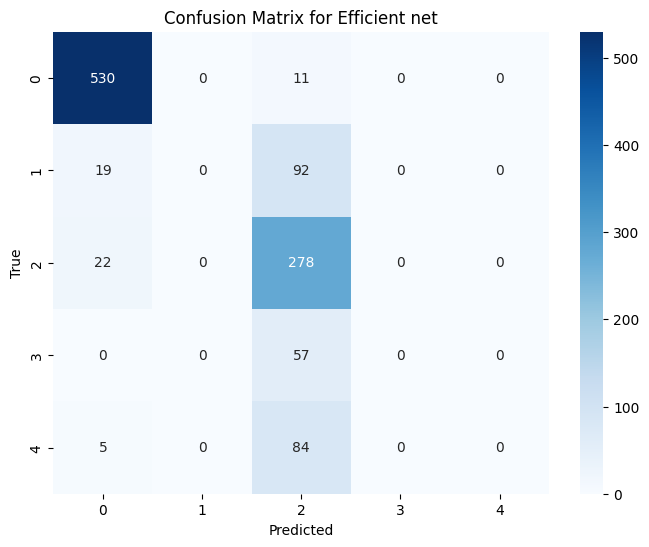

In [ ]:
if __name__ == '__main__':
    trained_model, train_losses, val_losses = main()